In [ ]:
!pip install hmmlearn
import numpy as np
import matplotlib.pyplot as plt
from hmmlearn import hmm

In [ ]:
states = ["Rainy", "Sunny"]
n_states = len(states)

In [ ]:
observations = ["Walk", "Shop", "Clean"]
n_observations = len(observations)

In [ ]:
model = hmm.CategoricalHMM(n_components=n_states, random_state=42)

In [ ]:
model.n_features = n_observations

In [ ]:
model.startprob_ = np.array([0.6, 0.4])

In [ ]:
model.transmat_ = np.array([
[0.7, 0.3],
[0.4, 0.6]
])

In [ ]:
model.emissionprob_ = np.array([
[0.1, 0.4, 0.5],
[0.6, 0.3, 0.1]
])

In [ ]:
observation_sequence = np.array([[0], [1], [2], [0], [0], [1], [2]])

In [ ]:
log_probability, hidden_state_sequence = model.decode(
observation_sequence,
algorithm="viterbi"
)

In [ ]:
print("Observation Sequence:")
for obs in observation_sequence:
    print(observations[obs[0]], end=" ")  # Indented

print("\n\nPredicted Hidden State Sequence:")
for state in hidden_state_sequence:
    print(states[state], end=" ")  # Indented

print("\n\nLog Probability of Sequence:", log_probability)


Observation Sequence:
Walk Shop Clean Walk Walk Shop Clean 

Predicted Hidden State Sequence:
Sunny Rainy Rainy Sunny Sunny Rainy Rainy 

Log Probability of Sequence: -9.92837320775803


In [ ]:
print("\n\nObservation and Predicted Weather:")
print("-----------------------------------")
for i in range(len(observation_sequence)):
    obs_name = observations[observation_sequence[i][0]]  # Indented
    state_name = states[hidden_state_sequence[i]]         # Indented
    print(f"Time {i+1}: Observation = {obs_name}, Predicted Weather = {state_name}")  # Indented




Observation and Predicted Weather:
-----------------------------------
Time 1: Observation = Walk, Predicted Weather = Sunny
Time 2: Observation = Shop, Predicted Weather = Rainy
Time 3: Observation = Clean, Predicted Weather = Rainy
Time 4: Observation = Walk, Predicted Weather = Sunny
Time 5: Observation = Walk, Predicted Weather = Sunny
Time 6: Observation = Shop, Predicted Weather = Rainy
Time 7: Observation = Clean, Predicted Weather = Rainy


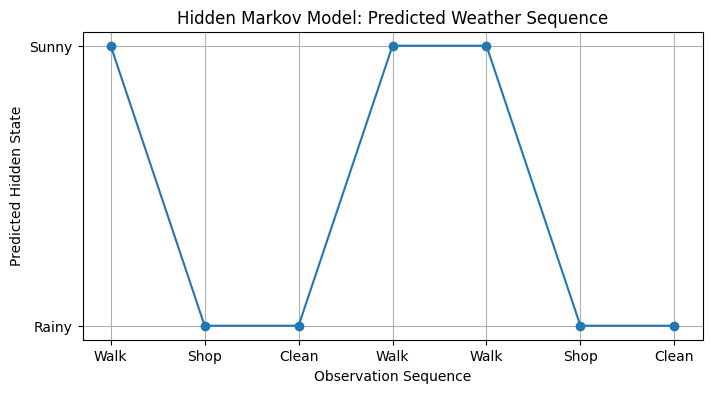

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(hidden_state_sequence, marker="o")
plt.yticks([0, 1], states)
plt.xticks(
range(len(observation_sequence)),
[observations[o[0]] for o in observation_sequence]
)
plt.xlabel("Observation Sequence")
plt.ylabel("Predicted Hidden State")
plt.title("Hidden Markov Model: Predicted Weather Sequence")
plt.grid(True)
plt.show()

In [ ]:
generated_observations, generated_states = model.sample(10)

print("\nGenerated Observation Sequence:")
for obs in generated_observations:
    print(observations[obs[0]], end=" ")

print("\n\nGenerated Hidden State Sequence:")
for state in generated_states:
    print(states[state], end=" ")


Generated Observation Sequence:
Clean Walk Shop Clean Clean Clean Walk Shop Clean Shop 

Generated Hidden State Sequence:
Rainy Sunny Rainy Rainy Rainy Rainy Sunny Rainy Rainy Rainy 